# Hälsostudie – Del 2: Fördjupning och pipeline

## Objektorienterad dataanalys

Klassen `HealthAnalyzer` har skapats för att genomföra
ytterligare analyser av datamaterialet från del 1.
Klassen innehåller metoder för att beräkna och
visualisera resultat.

In [1]:
import sys
import numpy as np
import pandas as pd
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))

from src.data_processing import load_data
from src.health_analyzer import HealthAnalyzer

df = load_data()
analyzer = HealthAnalyzer(df)

### 1. Medelålder efter kön

Syftet med analysen är att jämföra medelåldern
mellan kvinnor och män i datamaterialet.

In [2]:
analyzer.age_by_sex()

sex
F    49.868486
M    48.977330
Name: age, dtype: float64

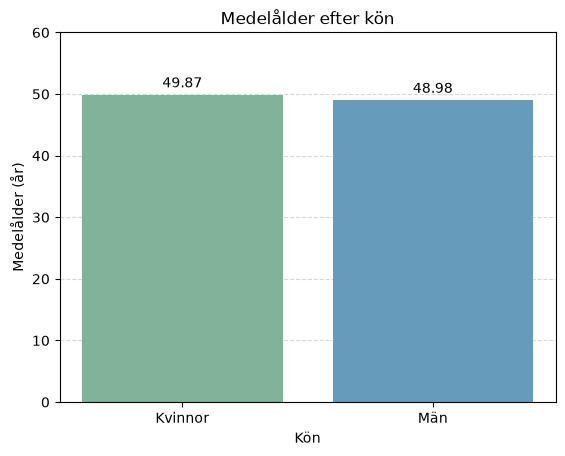

In [3]:
analyzer.plot_age_by_sex()

**Slutsats**

Medelåldern bland kvinnor är 49,87 år och bland
män 48,98 år. Skillnaden är mindre än ett år,
vilket visar att grupperna har ungefär samma
medelålder i datamaterialet.

### 2. Samband mellan ålder och systoliskt blodtryck

Syftet med analysen är att undersöka om det finns
ett samband mellan ålder och systoliskt blodtryck.
Resultatet visualiseras med ett spridningsdiagram.

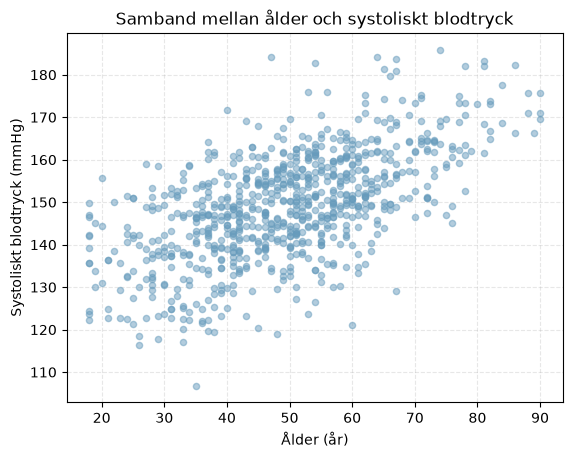

In [4]:
analyzer.blood_pressure_by_age()

**Slutsats**

Spridningsdiagrammet tyder på att det kan finnas
ett samband mellan ålder och systoliskt blodtryck.
Detta samband kommer att undersökas närmare
i avsnittet om regressionsanalys.

### 3. Sjukdomsförekomst bland rökare och icke-rökare

Syftet med analysen är att jämföra andelen personer
med sjukdom bland rökare och icke-rökare.

Eftersom grupperna är olika stora jämförs
procentandelar istället för absoluta antal.

In [5]:
analyzer.disease_by_smoking()

smoker
No     4.770017
Yes    8.920188
Name: disease, dtype: float64

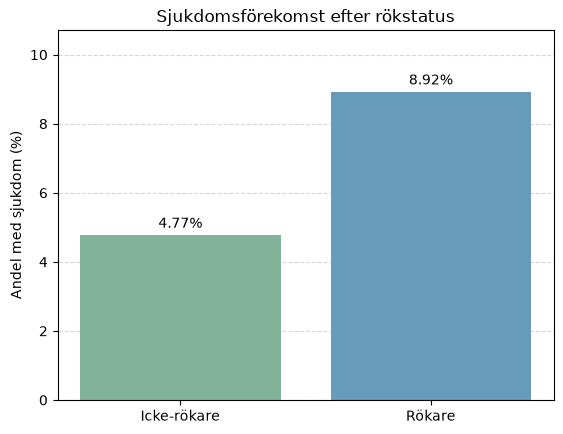

In [6]:
analyzer.plot_disease_by_smoking()

**Slutsats**

Andelen personer med sjukdom är 8,92 % bland rökare
och 4,77 % bland icke-rökare. Resultatet tyder på
ett möjligt samband mellan rökning och sjukdom.

För att undersöka om skillnaden är statistiskt
signifikant skulle en hypotesprövning kunna genomföras.
Detta ligger dock utanför ramen för denna analys.

## Multipel linjär regression – sambandet mellan ålder, vikt och systoliskt blodtryck

### 1. Beräkning av regressionskoefficienter

In [7]:
from src.regression import multiple_linear_regression

x_values = df[["age", "weight"]].to_numpy()
y_values = df["systolic_bp"].to_numpy()

beta = multiple_linear_regression(x_values, y_values)

print(f"Konstantterm: {beta[0]:.3f}")
print(f"Koefficient för ålder: {beta[1]:.3f}")
print(f"Koefficient för vikt: {beta[2]:.3f}")

Konstantterm: 109.499
Koefficient för ålder: 0.539
Koefficient för vikt: 0.178


### 2. Jämförelse mellan observerade och predikterade värden

In [8]:
from src.regression import predict

y_pred = predict(x_values, beta)

comparison = pd.DataFrame({
    "Ålder": df["age"],
    "Vikt (kg)": df["weight"],
    "Observerat blodtryck (mmHg)": y_values,
    "Predikterat blodtryck (mmHg)": y_pred,
    "Residual (mmHg)": y_values - y_pred
})

comparison.head().round(2)

,Ålder,Vikt (kg),Observerat blodtryck (mmHg),Predikterat blodtryck (mmHg),Residual (mmHg)
0,57,65.8,141.8,151.91,-10.11
1,47,95.9,144.8,151.87,-7.07
2,59,82.2,151.7,155.90,-4.20
3,72,93.1,151.0,164.84,-13.84
4,46,104.1,144.1,152.78,-8.68


### 3. Modellens förklaringsgrad (R²)

In [9]:
ss_res = np.sum((y_values - y_pred)**2)
ss_tot = np.sum((y_values - np.mean(y_values))**2)

r_squared = 1 - ss_res / ss_tot

print(f"Förklaringsgrad (R²): {r_squared:.3f}")
print(f"Förklarad variation: {r_squared:.1%}")

Förklaringsgrad (R²): 0.405
Förklarad variation: 40.5%


### 4. Visualisering och residualanalys

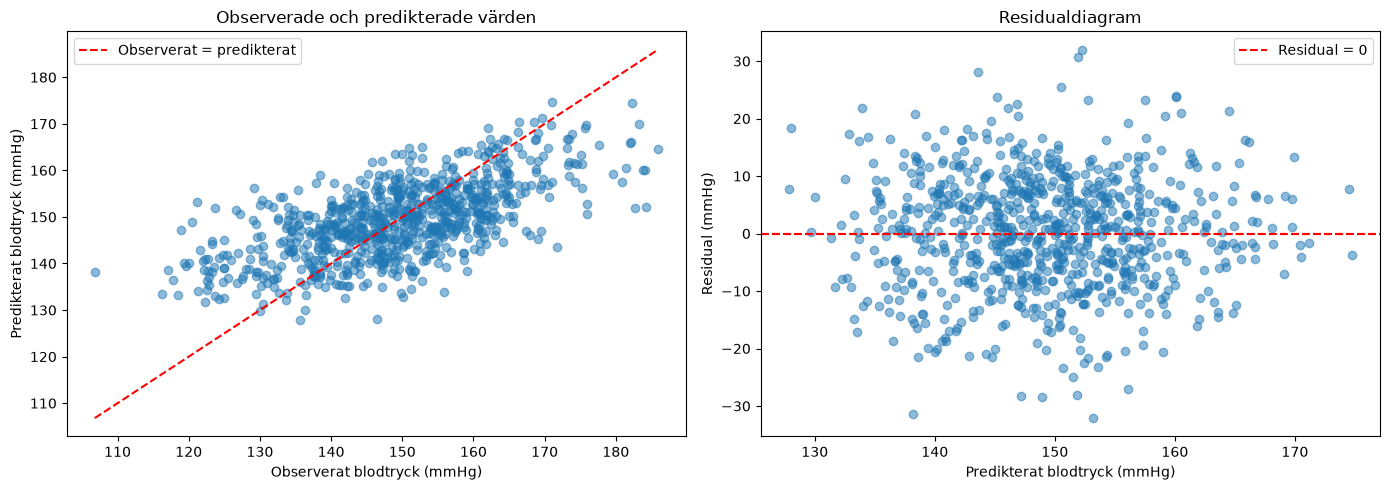

In [10]:
from src.regression import plot_regression_results

plot_regression_results(y_values, y_pred)

### Slutsats

Resultatet av den multipla linjära regressionen visar ett positivt samband mellan ålder, vikt och systoliskt blodtryck.

En ökning av åldern med ett år är förknippad med en ökning av det predikterade blodtrycket med cirka 0,54 mmHg vid oförändrad vikt. En viktökning med ett kilogram är förknippad med en ökning på cirka 0,18 mmHg vid oförändrad ålder.

Modellens förklaringsgrad (R²) är 0,405, vilket innebär att modellen förklarar 40,5 % av variationen i det systoliska blodtrycket.

Jämförelsen mellan observerade och predikterade värden visar att modellen tenderar att överskatta låga blodtrycksvärden och underskatta höga blodtrycksvärden.

Residualdiagrammet visar att residualerna är relativt jämnt fördelade kring noll utan något tydligt systematiskt mönster.

Sammantaget visar analysen att ålder och vikt kan bidra till att förklara variationen i blodtrycket, men att en stor del av variationen fortfarande är oförklarad. Andra faktorer kan därför också vara av betydelse.

Analysen har genomförts med stöd av kursens föreläsningar, undervisningsmaterial och den officiella dokumentationen för pandas, NumPy, SciPy och Matplotlib.